**Integrantes**
1. Honorio Menendez Sacaca
2. Alexander Vilcapaza Chavez
3. Jhony Fermin Quenta Chura

### **Actividad 00. Preparación del entorno**

In [ ]:
%pip -q install "pulp==3.3.2" scipy numpy matplotlib pandas plotly ipywidgets

In [ ]:
import pulp, scipy, numpy as np, matplotlib
print("PuLP     :", pulp.__version__)          # debe mostrar 3.3.2
print("SciPy    :", scipy.__version__)
print("Solvers  :", pulp.listSolvers(onlyAvailable=True))   # debe incluir PULP_CBC_CMD

PuLP     : 3.3.2
SciPy    : 1.16.3
Solvers  : ['PULP_CBC_CMD', 'HiGHS']


### **Actividad 01. Planta quesera: programación lineal y precios sombra**

In [ ]:
def planta_quesera(util_queso=9.0, util_yogur=2.5, leche=2400, mano_obra=2700, demanda=600):
    m = pulp.LpProblem("planta_quesera", pulp.LpMaximize)
    x1 = pulp.LpVariable("queso_kg", lowBound=0)
    x2 = pulp.LpVariable("yogur_L", lowBound=0)
    m += util_queso * x1 + util_yogur * x2, "utilidad"
    m += 8 * x1 + x2 <= leche, "leche"
    m += 6 * x1 + 3 * x2 <= mano_obra, "mano_obra"
    m += x2 <= demanda, "demanda_yogur"
    m.solve(pulp.PULP_CBC_CMD(msg=False))
    return m, x1, x2

m, x1, x2 = planta_quesera()
print("Estado :", pulp.LpStatus[m.status])
print("Queso  :", x1.value(), "kg   Yogur:", x2.value(), "L")
print("Z      : S/", pulp.value(m.objective))
for nombre, r in m.constraints.items():
    print(f"{nombre:15s} precio sombra = {r.pi:7.4f}   holgura = {r.slack:7.2f}")

Estado : Optimal
Queso  : 250.0 kg   Yogur: 400.0 L
Z      : S/ 3250.0
leche           precio sombra =  0.6667   holgura =   -0.00
mano_obra       precio sombra =  0.6111   holgura =   -0.00
demanda_yogur   precio sombra = -0.0000   holgura =  200.00


## **Respuestas**

**Tabla 1. Resultados y análisis de escenarios**

| Escenario | $x_1$ (kg) | $x_2$ (L) | Z (S/) | ¿Global? |
|---------|:---------:|:---------:|:---------:|---------|
| a) Caso base | 250 | 400 | 3250.00 | Leche y mano de obra |
| b) Utilidad del yogur sube a S/ 5,00 | 150 | 600 | 4350.00 | Mano de obra y demanda |
| c) La leche disponible sube a 2500 L | 266.66667 | 366.66667 | 3316.666705 | Leche y mano de obra |
| d) La demanda de yogur baja a 300 L | 262.5 | 300 | 3112.5 | Leche y demanda |

**1.	Compare el aumento de Z en el escenario (c) con el precio sombra de la leche en el caso base. ¿Coinciden? Explique por qué.**

Sí, coinciden. Al incrementar la disponibilidad de leche de 2,400 a 2,500 litros, la utilidad aumenta de S/ 3,250 a S/ 3,316.67, generando una diferencia de S/ 66.67. Este resultado corresponde al precio sombra de S/ 0.6667 por cada litro adicional de leche, manteniéndose dentro del rango de validez del modelo.

**2.	En el escenario (b) cambió la solución óptima. Ubique el nuevo vértice en la Figura 1 de la guía teórica y explique el cambio con la pendiente de la recta de isoutilidad.**

Al incrementar la utilidad del yogur de S/ 2.50 a S/ 5.00, cambia la pendiente de la recta de isoutilidad de -3.6 a -1.8. Esto hace más conveniente incrementar la producción de yogur, obteniendo una nueva solución óptima de 150 kg de queso y 600 litros de yogur, con una utilidad de S/ 4,350.

**3.	Un acopiador ofrece 300 L adicionales de leche a S/ 0,80 por litro. ¿Le conviene a la planta comprarlos? Use el modelo, no solo el precio sombra, y justifique.**

No conviene comprar los 300 litros adicionales de leche. Al ejecutar nuevamente el modelo con una disponibilidad de 2,700 litros, la utilidad aumenta a S/ 3,450, lo que representa un incremento de S/ 200 respecto al caso base. Sin embargo, la compra de leche representa un costo de S/ 240, generando una diferencia negativa de S/ 40. Por lo tanto, la adquisición no resulta rentable para la planta.

### **Actividad 02. Distribución desde acopio: modelo con índices**

In [ ]:
import pulp

I = ["Juliaca", "Ayaviri"]
J = ["Puno", "Ilave", "Azangaro"]
oferta  = {"Juliaca": 60, "Ayaviri": 40}
demanda = {"Puno": 45, "Ilave": 25, "Azangaro": 25}
costo = {("Juliaca", "Puno"): 18, ("Juliaca", "Ilave"): 30, ("Juliaca", "Azangaro"): 22,
         ("Ayaviri", "Puno"): 35, ("Ayaviri", "Ilave"): 48, ("Ayaviri", "Azangaro"): 20}

m = pulp.LpProblem("transporte_acopio", pulp.LpMinimize)
x = pulp.LpVariable.dicts("x", (I, J), lowBound=0)       # toneladas de i a j

m += pulp.lpSum(costo[i, j] * x[i][j] for i in I for j in J), "costo_total"

# TODO 1: restricción de oferta para cada almacén i (lo enviado no supera la oferta)
for i in I:
    m += pulp.lpSum(x[i][j] for j in J) <= oferta[i], f"oferta_{i}"

# TODO 2: restricción de demanda para cada mercado j (lo recibido cubre la demanda)
for j in J:
    m += pulp.lpSum(x[i][j] for i in I) >= demanda[j], f"demanda_{j}"

m.solve(pulp.PULP_CBC_CMD(msg=False))
print(pulp.LpStatus[m.status], " Costo total: S/", pulp.value(m.objective))
for i in I:
    print(i, [x[i][j].value() for j in J])

Optimal  Costo total: S/ 2230.0
Juliaca [35.0, 25.0, 0.0]
Ayaviri [10.0, 0.0, 25.0]


## **Respuestas**
**Tabla 3. Plan óptimo de envíos**

| Envío (t) | Puno | Ilave | Azángaro | Total enviado |
|---|---:|---:|---:|---:|
| Juliaca | 35 | 25 | 0 | 60 |
| Ayaviri | 10 | 0 | 25 | 35 |
| **Total recibido** | **45** | **25** | **25** | **95** |

**1.	¿Qué almacén queda con capacidad sin usar y cuánta? ¿Qué indica eso sobre su precio sombra?**

Ayaviri usa 35 de sus 40 toneladas y conserva 5 t. Su oferta no es una restricción activa, por tanto su precio sombra es S/ 0 por tonelada: aumentar marginalmente su capacidad, manteniendo los demás datos, no reduce el costo óptimo.

**2.	Interprete el precio sombra de la demanda de Ilave: ¿cuánto aumentaría el costo total si Ilave pidiera una tonelada más?**

Es aproximadamente S/ 47 por tonelada. Si Ilave solicita una tonelada adicional (26 t), el costo mínimo aumenta de S/ 2230 a S/ 2277, manteniendo válidas las mismas condiciones marginales. Lo comprobamos modificando únicamente la demanda.

**3.	Agregue un tercer almacén en Ilave con oferta de 15 t y costos 25, 5 y 40 hacia Puno, Ilave y Azángaro. Modifique solo los datos, no el modelo, y reporte el nuevo costo total.**

| Envío (t) | Puno | Ilave | Azángaro | Total enviado |
|---|:---:|:---:|:---:|:---:|
| Juliaca | 45.0 | 25.0 | 0.0 | 55.0 |
| Ayaviri | 0.0 | 0.0 | 25.0 | 25.0 |
| Ilave | 0.0 | 15.0 | 0.0 | 15.0 |

El nuevo costo mínimo es S/ 1685 por semana, lo cual representa un ahorro de S/ 545 respecto del caso base. Un plan óptimo es: Juliaca → Puno 45 t y → Ilave 10 t; Ayaviri → Azángaro 25 t; nuevo almacén Ilave → Ilave 15 t.


### **Actividad 03. Microservicios: modelo binario y enumeración**

In [ ]:
import pulp, itertools, time

servicios  = {"Autenticacion": (2, 4), "Pagos": (4, 8), "Catalogo": (2, 6),
              "Reportes": (6, 12), "Notificaciones": (1, 2)}          # (vCPU, RAM GB)
servidores = {"S1": (8, 16, 120), "S2": (8, 16, 120), "S3": (16, 32, 260)}   # (vCPU, RAM, S/ mes)

def consolidar(restricciones_extra=None):
    m = pulp.LpProblem("microservicios", pulp.LpMinimize)
    y = pulp.LpVariable.dicts("y", servidores, cat="Binary")
    z = pulp.LpVariable.dicts("z", (servicios, servidores), cat="Binary")
    m += pulp.lpSum(servidores[j][2] * y[j] for j in servidores)

    # TODO 1: cada servicio se asigna exactamente a un servidor
    for i in servicios:
        m += pulp.lpSum(z[i][j] for j in servidores) == 1, f"asig_{i}"

    # TODO 2: capacidad de vCPU de cada servidor, activada por y[j]
    for j in servidores:
        m += pulp.lpSum(servicios[i][0] * z[i][j] for i in servicios) <= servidores[j][0] * y[j], f"vcpu_{j}"

    # TODO 3: capacidad de RAM de cada servidor, activada por y[j]
    for j in servidores:
        m += pulp.lpSum(servicios[i][1] * z[i][j] for i in servicios) <= servidores[j][1] * y[j], f"ram_{j}"

    if restricciones_extra:
        restricciones_extra(m, y, z)
    m.solve(pulp.PULP_CBC_CMD(msg=False))
    asignacion = {i: j for i in servicios for j in servidores if z[i][j].value() > 0.5}
    return pulp.value(m.objective), asignacion

t0 = time.perf_counter(); costo, asig = consolidar(); t1 = time.perf_counter()
print("PuLP:", costo, asig, f"{t1 - t0:.3f} s")

# Enumeración exhaustiva: revisa las 243 asignaciones posibles
def enumerar():
    mejor = None
    for combo in itertools.product(servidores, repeat=len(servicios)):
        carga = {}
        for (s, req), j in zip(servicios.items(), combo):
            c, r = carga.get(j, (0, 0)); carga[j] = (c + req[0], r + req[1])
        if all(carga[j][0] <= servidores[j][0] and carga[j][1] <= servidores[j][1] for j in carga):
            costo = sum(servidores[j][2] for j in carga)
            if mejor is None or costo < mejor[0]:
                mejor = (costo, dict(zip(servicios, combo)))
    return mejor

print("Enumeración:", enumerar())

PuLP: 240.0 {'Autenticacion': 'S2', 'Pagos': 'S1', 'Catalogo': 'S1', 'Reportes': 'S2', 'Notificaciones': 'S1'} 0.014 s
Enumeración: (240, {'Autenticacion': 'S1', 'Pagos': 'S2', 'Catalogo': 'S2', 'Reportes': 'S1', 'Notificaciones': 'S2'})


In [ ]:
def anti_afinidad(m, y, z):
    for j in servidores:
        m += z["Autenticacion"][j] + z["Reportes"][j] <= 1, f"separar_{j}"

print(consolidar(anti_afinidad))

(380.0, {'Autenticacion': 'S3', 'Pagos': 'S3', 'Catalogo': 'S3', 'Reportes': 'S1', 'Notificaciones': 'S1'})


## **Respuestas**

**Tabla 4. Comparación de resultados**

| Escenario | Costos (S/) | Servidores contratados | Tiempo (s) |
|:---------|:---------:|:---------:|:---------:|
| PuLP, caso base | 240.0 | S1, S2 | 0.01192 |
| Enumeración, caso base | 240.0 | S1, S2 | 0.00108 |
| PuLP, con anti-afinidad | 380.0 | S1, S3 | 0.01929 |

**1. ¿Cuánto cuesta la exigencia de seguridad? ¿Por qué no se pueden usar solo S1 y S2?**  

El costo sube de **S/ 240** a **S/ 380 mensuales**: **S/ 140 adicionales**. La RAM total exigida es 32 GB, exactamente lo que suman S1 y S2 (16 + 16). Reportes requiere 12 GB. Si no puede compartir servidor con Autenticación (4 GB), los demás microservicios que podrían acompañar a Reportes requieren 2, 6 u 8 GB; la única opción sin exceder 16 GB deja al menos 2 GB sin usar. Por eso **no alcanza la capacidad total utilizable** de S1 y S2 para cubrir los 32 GB requeridos. Es necesario contratar un servidor adicional o uno de mayor capacidad. La combinación óptima es **S3 y uno de los servidores pequeños**, a S/ 380.

**2.	Si hubiera 12 servicios y 4 tipos de servidor, ¿cuántas asignaciones tendría que revisar la enumeración? Estime el tiempo con base en lo que midió.**  

$4^{12}=\mathbf{16\,777\,216}$ combinaciones. Es unas **69 050 veces** más que las 243 del ejercicio base. La extrapolación de tiempo se calcula a continuación; es aproximada porque cada combinación podría costar distinto en otro problema y la medición de 243 casos es muy corta.

### **Actividad 04. Convexidad y óptimos locales con SciPy**

In [ ]:
import numpy as np

H = np.array([[2, 1],
              [1, 4]])                  # hessiana de f(x1, x2) = x1^2 + x1*x2 + 2*x2^2
print("Valores propios de f:", np.linalg.eigvalsh(H))

# TODO: escriba la hessiana de h(x1, x2) = x1^2 + 4*x1*x2 + x2^2, calcule sus
#       valores propios y concluya si h es convexa.

H_h = np.array([[2, 4],
                [4, 2]])

valores_propios_h = np.linalg.eigvalsh(H_h)
print("Valores propios de h:", valores_propios_h)

if np.all(valores_propios_h >= 0):
    print("Conclusión: h(x1, x2) ES CONVEXA porque todos sus valores propios son no negativos.")
else:
    print("Conclusión: h(x1, x2) NO ES CONVEXA porque posee un valor propio negativo (", valores_propios_h[0], ").")

Valores propios de f: [1.58578644 4.41421356]
Valores propios de h: [-2.  6.]
Conclusión: h(x1, x2) NO ES CONVEXA porque posee un valor propio negativo ( -2.0 ).


x0 = -2.000 -> x* = -1.4730   g(x*) =  -5.4442   iteraciones = 6
x0 = -1.000 -> x* = -1.4730   g(x*) =  -5.4442   iteraciones = 6
x0 = -0.500 -> x* = -1.4730   g(x*) =  -5.4442   iteraciones = 4
x0 =  0.000 -> x* = -1.4730   g(x*) =  -5.4442   iteraciones = 4
x0 =  0.126 -> x* =  0.1260   g(x*) =   0.0627   iteraciones = 0
x0 =  0.500 -> x* =  1.3470   g(x*) =  -2.6186   iteraciones = 3
x0 =  1.000 -> x* =  1.3470   g(x*) =  -2.6186   iteraciones = 5
x0 =  2.000 -> x* =  1.3470   g(x*) =  -2.6186   iteraciones = 7


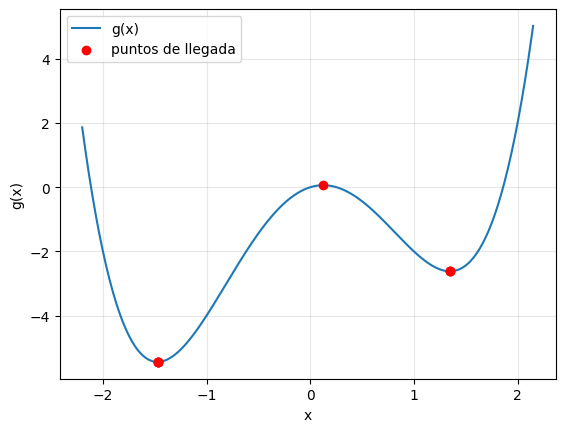

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

g  = lambda x: x[0]**4 - 4*x[0]**2 + x[0]
dg = lambda x: np.array([4*x[0]**3 - 8*x[0] + 1])

resultados = []
for x0 in [-2, -1, -0.5, 0, 0.126, 0.5, 1, 2]:
    r = minimize(g, [x0], jac=dg, method="BFGS")
    resultados.append((x0, r.x[0], r.fun, r.nit))
    print(f"x0 = {x0:6.3f} -> x* = {r.x[0]:7.4f}   g(x*) = {r.fun:8.4f}   iteraciones = {r.nit}")

xs = np.linspace(-2.2, 2.15, 400)
plt.plot(xs, xs**4 - 4*xs**2 + xs, label="g(x)")
plt.scatter([r[1] for r in resultados], [r[2] for r in resultados], color="red", zorder=3, label="puntos de llegada")
plt.xlabel("x");
plt.ylabel("g(x)");
plt.legend();
plt.grid(alpha=0.3);
plt.show()

## **Respuestas**

**Tabla 5. Resultados del arranque múltiple**

| $x_0$ | $x^*$ alcanzado | $g(x^*)$ | Iteraciones | ¿Global? |
|:---------:|:---------:|:---------:|:---------:|---------|
| −2 | −1.4730 | −5.4442 | 6 | Sí |
| −0.5 | −1.4730 | −5.4442 | 4 | Sí |
| 0.126 | 0.1260 | 0.0627 | 0 | No: máximo local |
| 0.5 | 1.3470 | −2.6186 | 6 | No |
| 1 | 1.3470 | −2.6186 | 5 | No |
| 2 | 1.3470 | −2.6186 | 7 | No |

**1. Explique el resultado obtenido con $x_0 = 0,126$. ¿Por qué el método no se mueve? Relacione su respuesta con la condición $∇g(x) = 0$.**  

Porque **$g'(0.126)$ es prácticamente 0** (el valor no es exactamente una raíz, pero está muy cerca). BFGS emplea la condición de gradiente pequeño como un criterio de parada, por lo que puede detenerse en la iteración 0. La segunda derivada allí es **negativa** ($g''\approx-7.809$): es un **máximo local**, no un mínimo. Tener gradiente nulo **no demuestra** que se haya encontrado el mínimo global, ni siquiera un mínimo local.

**2. Proponga una regla simple para elegir puntos de inicio que aumente la probabilidad de hallar el mínimo global. ¿Qué costo tiene esa regla cuando el problema tiene 1000 variables?**

Usar **varios puntos iniciales distribuidos por distintas regiones**, ejecutar el método desde cada uno y conservar el valor objetivo menor. Aumenta la posibilidad de encontrar un mínimo mejor, pero consume tiempo aproximadamente proporcional al número de arranques. Una malla con solo 3 niveles por variable tendría $3^{1000}$ combinaciones: es computacionalmente inviable.

**3.	¿Cómo se conecta esta experiencia con la necesidad de metaheurísticas en la Unidad II?**  

En problemas no convexos, un método local depende del inicio y puede detenerse en mínimos subóptimos (o puntos estacionarios no mínimos). Las metaheurísticas amplían la exploración del espacio y ayudan a evitar quedar atrapados en una sola región, aunque **no garantizan** obtener el óptimo global.